# Empirical Water Boiling Point Altitude Dataset Demo

This notebook demonstrates the empirical water boiling point vs. altitude dataset compiled from authoritative historical and engineering sources (Forbes 1857 Alps measurements, Law Supply engineering tables, UC Davis/Snyder 2016 calibration tables, Engineering ToolBox, and SimuPipe ISA theoretical baseline).

### What this artifact does:
- Loads standardized water boiling point measurements and reference values against altitude and ambient pressure.
- Validates empirical measurements against the International Standard Atmosphere (ISA) barometric formula and the Antoine vapor pressure equation.
- Visualizes the relationship between altitude, pressure, and boiling point across different historical and engineering datasets.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'matplotlib==3.10.0', 'seaborn==0.13.2', 'scipy==1.16.3')

In [2]:
import json
import urllib.request
import http.client
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# One colour per role, the same in every notebook of this run and in the paper's figures.
COLOURS = {
    "method": "#0173B2",  # the paper's own method, model or condition
    "baseline": "#949494",  # the main baseline, control or reference
    "other_1": "#DE8F05",  # the first further comparator
    "other_2": "#029E73",  # the second
    "other_3": "#CC78BC",  # the third
    "other_4": "#CA9161",  # the fourth
    "other_5": "#56B4E9",  # the fifth
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})

Matplotlib is building the font cache; this may take a moment.


### Data Loading Helper
We load data from the GitHub raw URL with fallback to local `mini_demo_data.json`.

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-daa948-boiling-point-prediction-error-as/main/round-2/dataset-1/demo/mini_demo_data.json"

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(f"Loaded dataset metadata: {data['metadata']}")
print(f"Number of source datasets: {len(data['datasets'])}")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Loaded dataset metadata: {'description': 'Empirical and theoretical water boiling point vs altitude data for ISA/Antoine validation', 'total_examples': 129, 'num_datasets': 5, 'task': 'Predict boiling point of water given altitude and ambient pressure', 'domain': 'Atmospheric thermodynamics', 'evaluation_metric': 'RMSE (°C) between predicted and measured boiling point'}
Number of source datasets: 3


### Configuration
Tunable parameters for demonstration and analysis.

In [5]:
# Configuration parameters
MAX_SAMPLES_PER_DATASET = 10  # Can be scaled up
ISA_SEA_LEVEL_PRESSURE = 1013.25  # hPa
ANTOINE_A = 8.07131
ANTOINE_B = 1730.63
ANTOINE_C = 233.426

### Processing and Validation
Parse the JSON examples into a clean DataFrame and compute ISA barometric pressure and Antoine equation predictions.

In [6]:
records = []
for ds in data["datasets"]:
    ds_name = ds["dataset"]
    for ex in ds["examples"][:MAX_SAMPLES_PER_DATASET]:
        inp = json.loads(ex["input"])
        out = json.loads(ex["output"])
        records.append({
            "dataset": ds_name,
            "altitude_m": inp.get("altitude_m"),
            "pressure_hpa": inp.get("pressure_hpa"),
            "boiling_point_c": out.get("boiling_point_c"),
            "source_detail": ex.get("metadata_source_detail"),
            "is_empirical": ex.get("metadata_is_empirical")
        })

df = pd.DataFrame(records)

# ISA barometric formula: P = 1013.25 * (1 - 2.25577e-5 * h)^5.25588
def isa_pressure(h):
    if h is None:
        return None
    return 1013.25 * (1 - 2.25577e-5 * h) ** 5.25588

# Antoine equation for water: log10(P_mmHg) = A - B / (C + T)
# T = B / (A - log10(P_mmHg)) - C
def antoine_temp(p_hpa):
    if p_hpa is None:
        return None
    p_mmhg = p_hpa / 1.33322
    return ANTOINE_B / (ANTOINE_A - np.log10(p_mmhg)) - ANTOINE_C

df["pressure_isa_hpa"] = df["altitude_m"].apply(isa_pressure)
df["boiling_point_antoine_c"] = df["pressure_hpa"].apply(antoine_temp)
df["bp_error_c"] = df["boiling_point_c"] - df["boiling_point_antoine_c"]

print(df.head(10))
print(f"\nSummary statistics of boiling point error vs Antoine (°C):")
print(df["bp_error_c"].describe())

                 dataset  altitude_m  pressure_hpa  boiling_point_c  \
0       Forbes_1857_Alps      2966.2         704.1             90.3   
1       Forbes_1857_Alps      2966.2         704.1             90.2   
2       Forbes_1857_Alps      2376.7         758.5             92.2   
3  LawSupply_Engineering      -304.8        1049.8            101.0   
4  LawSupply_Engineering      -152.4        1032.8            100.5   
5  LawSupply_Engineering         0.0        1012.5            100.0   
6    UCDavis_Snyder_2016      -152.4        1031.7            100.5   
7    UCDavis_Snyder_2016         0.0        1013.2            100.0   
8    UCDavis_Snyder_2016       152.4         995.1             99.5   

                                       source_detail  is_empirical  \
0  Transactions of the Royal Society of Edinburgh...          True   
1  Transactions of the Royal Society of Edinburgh...          True   
2  Transactions of the Royal Society of Edinburgh...          True   
3  Web pa

### Results and Visualization
Visualize the relationship between altitude and boiling point across the different datasets, comparing empirical measurements with theoretical models.

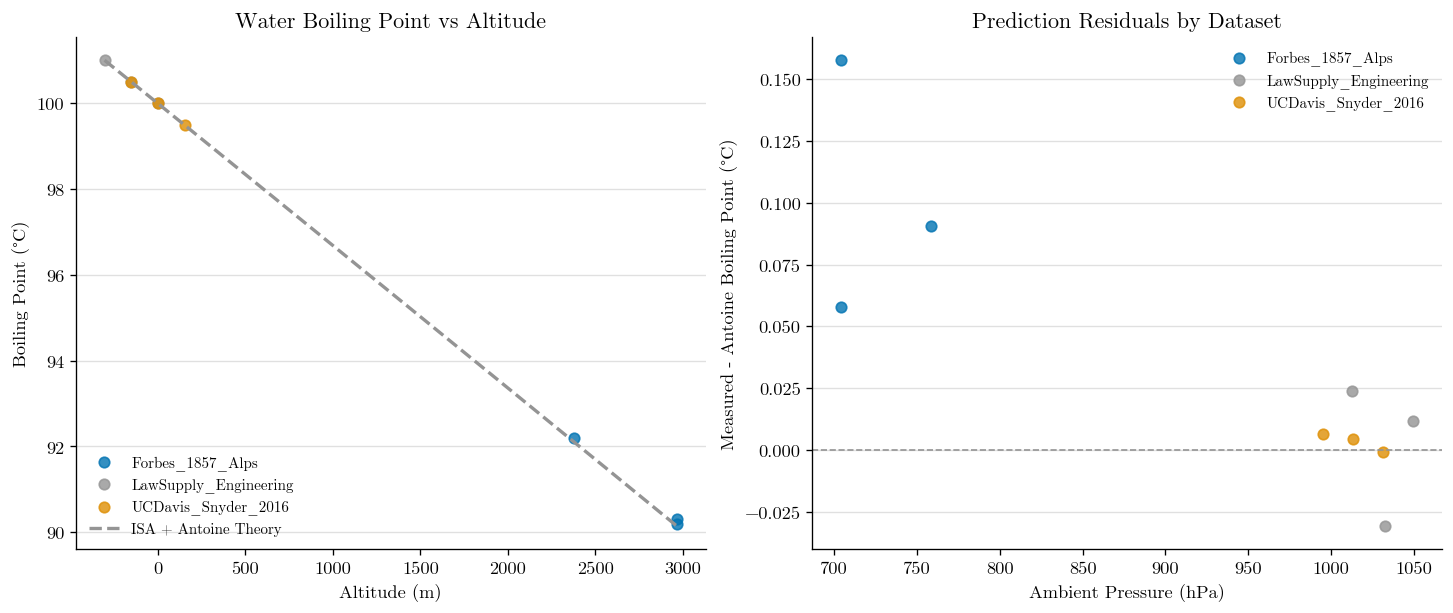

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Altitude vs Boiling Point
ax = axes[0]
for i, (name, group) in enumerate(df.groupby("dataset")):
    color_key = list(COLOURS.keys())[i % len(COLOURS)]
    ax.scatter(group["altitude_m"], group["boiling_point_c"], label=name, color=COLOURS[color_key], alpha=0.8, s=40)

# Theoretical curve
alt_range = np.linspace(df["altitude_m"].min(), df["altitude_m"].max(), 100)
p_range = [isa_pressure(h) for h in alt_range]
t_range = [antoine_temp(p) for p in p_range]
ax.plot(alt_range, t_range, color=COLOURS["baseline"], linestyle="--", label="ISA + Antoine Theory", linewidth=2)

ax.set_xlabel("Altitude (m)")
ax.set_ylabel("Boiling Point (°C)")
ax.set_title("Water Boiling Point vs Altitude")
ax.legend(fontsize=9, loc="lower left")

# Plot 2: Pressure vs Boiling Point Error
ax2 = axes[1]
for i, (name, group) in enumerate(df.groupby("dataset")):
    color_key = list(COLOURS.keys())[i % len(COLOURS)]
    ax2.scatter(group["pressure_hpa"], group["bp_error_c"], label=name, color=COLOURS[color_key], alpha=0.8, s=40)

ax2.axhline(0, color=COLOURS["baseline"], linestyle="--", linewidth=1)
ax2.set_xlabel("Ambient Pressure (hPa)")
ax2.set_ylabel("Measured - Antoine Boiling Point (°C)")
ax2.set_title("Prediction Residuals by Dataset")
ax2.legend(fontsize=9, loc="upper right")

plt.show()